In [4]:
from ase.io import read
import numpy as np
import diffraction as diff
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import time as time
from matplotlib.widgets import Button
import scipy.io
from matplotlib.widgets import RangeSlider
import scipy.ndimage as ndimage
import matplotlib.patheffects as path_effects
from CifFile import ReadCif
from scipy.optimize import curve_fit
import os

In [200]:
# use thetax and thetay to adjust initial orientation of the sample
thetax=np.pi/2*1

thetay=np.pi/2*0.1
hkl_dimension=10

# sigma_theta, if you need a small number for single crystal, input~0.01, if you need infinity, input~1000
sigma1=0.075

# sigma_phi
sigma2=1000

# sigma_r, use this to tune the peak linewidth
sigma3=0.003

# settings for imagine plane
resolutionx=200
qxymax=1.8
qxymin=0
qzmax=1.8
qzmin=0

# resolutionx+=2
resolutionz=int(resolutionx/qxymax*qzmax)
gridx,gridz=np.meshgrid(np.linspace(qxymin,qxymax,resolutionx),np.linspace(qzmin,qzmax,resolutionz))

In [201]:
# read crystal structure(POSCAR file which can be converted easily from cif on VESTA)
dirr = '../Huilong/'
filename = 'Orientation1'
address = dirr + filename +'.cif'
# cf = ReadCif(address)

a1,a2,a3,positions=diff.read_poscar(address) # example (graphite)
# a1,a2,a3,positions=diff.read_poscar(address) # example (graphite)

Bpeaks,Mqxy,Mqz,I_miller = diff.Bragg_peaks(a1,a2,a3,positions,thetax,thetay,hkl_dimension)
# Bpeaks = diff.diffuse(a1,a2,a3,positions,thetax,thetay,hkl_dimension,0)
# Bpeaks.shape


[[1.1700e+02 5.2350e-02 9.2342e-01 7.5040e-02]
 [1.1700e+02 6.6260e-02 9.1655e-01 5.8121e-01]
 [1.1700e+02 5.6636e-01 9.1663e-01 8.1270e-02]
 [1.1700e+02 5.5212e-01 9.2355e-01 5.7524e-01]
 [1.6700e+02 2.7675e-01 2.0986e-01 2.7592e-01]
 [1.6700e+02 2.8331e-01 2.0253e-01 7.7307e-01]
 [1.6700e+02 7.8338e-01 2.0237e-01 2.7336e-01]
 [1.6700e+02 7.7659e-01 2.0997e-01 7.7600e-01]
 [1.1400e+02 2.7317e-01 1.8948e-01 6.1440e-02]
 [1.1400e+02 2.5850e-01 2.0908e-01 4.9677e-01]
 [1.1400e+02 7.5862e-01 2.0867e-01 9.9696e-01]
 [1.1400e+02 7.7296e-01 1.9008e-01 5.6139e-01]
 [1.1400e+02 3.4154e-01 9.0051e-01 3.4284e-01]
 [1.1400e+02 3.3591e-01 8.9398e-01 8.4776e-01]
 [1.1400e+02 8.3598e-01 8.9379e-01 3.4795e-01]
 [1.1400e+02 8.4137e-01 9.0053e-01 8.4257e-01]
 [1.1400e+02 8.0700e-03 1.8553e-01 2.8496e-01]
 [1.1400e+02 5.9800e-02 2.0036e-01 7.8616e-01]
 [1.1400e+02 5.5989e-01 2.0023e-01 2.8657e-01]
 [1.1400e+02 5.0797e-01 1.8582e-01 7.8488e-01]
 [2.7000e+01 2.3521e-01 4.6912e-01 2.1121e-01]
 [2.7000e+01 

In [202]:
t1_start = time.process_time()
# calculated GIWAXS pattern
III=diff.intensity(gridx,gridz,Bpeaks,sigma1,sigma2,sigma3,hkl_dimension)
t1_stop = time.process_time()
print('cpu time =')


print(t1_stop-t1_start,'s')

cpu time =
6.767241000000013 s


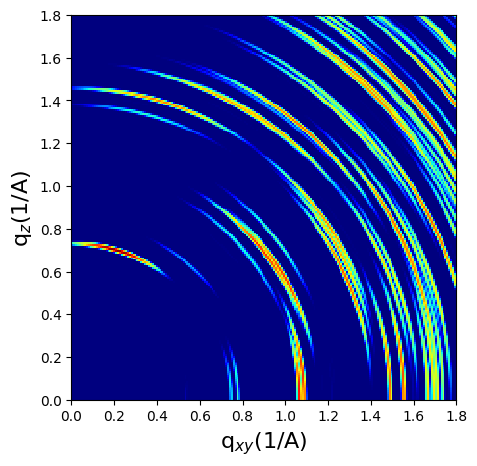

In [203]:
 # make the plot
colorbar=1 # upper limit
    
II1=np.log(III+1)

# II1=III

fig,ax=plt.subplots(figsize=(14,14))

plt.imshow(II1, interpolation='nearest', cmap=cm.jet,
               origin='lower', extent=[qxymin, qxymax, qzmin, qzmax],
               vmax=colorbar*II1.max(), vmin=II1.min())
ax.set_xlabel('q$_{xy}$(1/A)',fontsize=16)
ax.set_ylabel('q$_{z}$(1/A)',fontsize=16)
# ax.set_title(filename+' GIWAXS simulation',fontsize=16)
# ax.set_title('Reversed GIWAXS problem',fontsize=16)
fig.set_size_inches([5,5])
# plt.savefig(dirr + filename +'_1' +'.pdf')
# plt.savefig('2anc2_log.pdf')
# scipy.io.savemat(dirr+filename+'.mat', {'a': III})